In [2]:
from ctypes import *

import os


import time

import matplotlib.pyplot as plt

import pyvisa

from scipy.optimize import curve_fit

import scipy.fft as fft

from Instruments.atsapi import *

import shutil

In [3]:
class measuredIQ:
    def __init__(self, chopping_freq, filepath):
        self.chopping_freq = chopping_freq

        self.IQvoltage = np.loadtxt(filepath, delimiter= ',', skiprows= 1)

        self.I = self.IQvoltage[:, 0]

        self.Q = self.IQvoltage[:, 1]

        self.num_points = len(self.I)

        self.time = np.linspace(0, len(self.I))/chopping_freq

    def plot_slice(self, slice):
        plt.plot(self.time[0:slice], self.I[0:slice], label = "I")
        plt.plot(self.time[0:slice],self.Q[0:slice], label = "Q")
        plt.xlabel("Time (s)")
        plt.ylabel("Voltage (V)")
        plt.legend()
        plt.show()

    def return_phase(self, unwrapped = True):
        if unwrapped:
            self.phase = np.arctan(self.Q/self.I)
        else:
            self.phase = np.arctan2(self.Q, self.I)
        print(unwrapped)

    def return_magnitude(self):
        self.mag = np.sqrt(self.I**2 + self.Q**2)

    def phase_fft(self):
        self.yf_phase = np.abs(fft.rfft(self.phase))
        self.xf_phase = fft.rfftfreq(len(self.phase), 1/self.chopping_freq)

    def magnitude_fft(self):
        self.yf_mag = np.abs(fft.rfft(self.mag))
        self.xf_mag = fft.rfftfreq(len(self.mag), 1/self.chopping_freq)

    def magnitude_psd(self):
        self.psd_mag = (self.yf_mag**2)/(len(self.mag)*self.chopping_freq)
    
    def phase_psd(self):
        self.psd_phase = (self.yf_phase**2)/(len(self.phase)*self.chopping_freq)

In [88]:
noise_floorffts_newmix = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmixdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_newmix[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_newmix.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_newmix = []

total_magyf_newmix = []

total_ppsd_newmix = []

total_mpsd_newmix = []

for value in noise_floorffts_newmix.values():
    total_phaseyf_newmix.append(value.yf_phase)

    total_magyf_newmix.append(value.yf_mag)

    total_ppsd_newmix.append(value.psd_phase)

    total_mpsd_newmix.append(value.psd_mag)


total_phaseyf_newmix = np.array(np.average(total_phaseyf_newmix, axis = 0))

total_magyf_newmix = np.array(np.average(total_magyf_newmix, axis = 0))

total_ppsd_newmix = np.array(np.average(total_ppsd_newmix, axis = 0))

total_mpsd_newmix = np.array(np.average(total_mpsd_newmix, axis = 0))

In [89]:
noise_floorffts_oldmix = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01222026_correctlodownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_oldmix[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_oldmix.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_oldmix = []

total_magyf_oldmix = []

total_ppsd_oldmix = []

total_mpsd_oldmix = []

for value in noise_floorffts_oldmix.values():
    total_phaseyf_oldmix.append(value.yf_phase)

    total_magyf_oldmix.append(value.yf_mag)

    total_ppsd_oldmix.append(value.psd_phase)

    total_mpsd_oldmix.append(value.psd_mag)


total_phaseyf_oldmix = np.array(np.average(total_phaseyf_oldmix, axis = 0))

total_magyf_oldmix = np.array(np.average(total_magyf_oldmix, axis = 0))

total_ppsd_oldmix = np.array(np.average(total_ppsd_oldmix, axis = 0))

total_mpsd_oldmix = np.array(np.average(total_mpsd_oldmix, axis = 0))

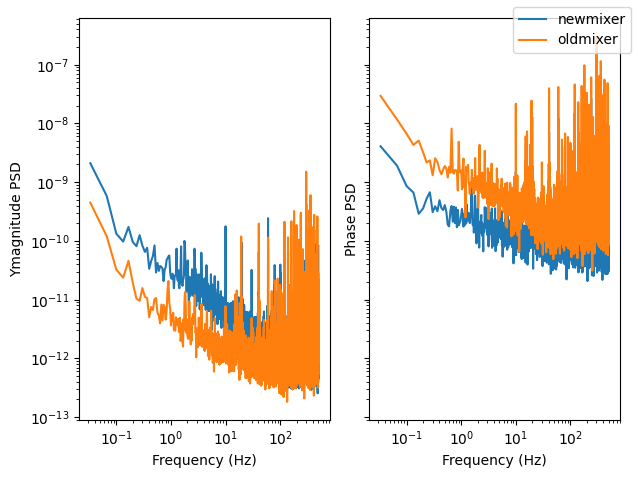

In [90]:
xf_overall_newmix = noise_floorffts_newmix["0_downsampled.csv"].xf_phase

xf_overall_oldmix = noise_floorffts_oldmix["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_newmix["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_newmix[1:], (total_magyf_newmix[1:]**2)/(num_points*1E3), label = "newmixer")
ax1.loglog(xf_overall_oldmix[1:], (total_magyf_oldmix[1:]**2)/(num_points*1E3), label = "oldmixer")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_newmix[1:], (total_phaseyf_newmix[1:]**2)/(num_points*1E3))
ax2.loglog(xf_overall_oldmix[1:],(total_phaseyf_oldmix[1:]**2)/(num_points*1E3))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

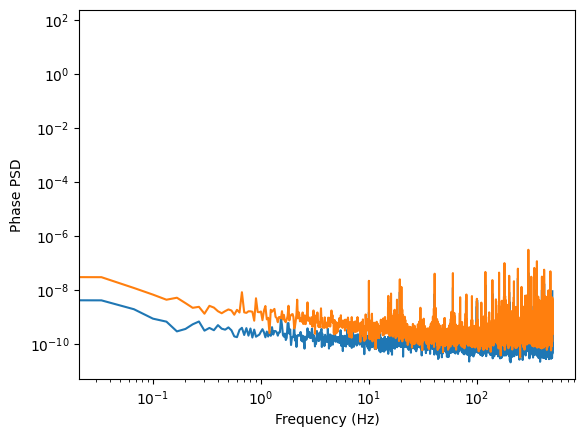

In [39]:
plt.loglog(xf_overall_newmix, (total_phaseyf_newmix**2)/(num_points*1E3), label = "newmixer")
plt.loglog(xf_overall_oldmix, (total_phaseyf_oldmix**2)/(num_points*1E3), label = "oldmixer")
plt.ylabel("Phase PSD")
plt.xlabel("Frequency (Hz)")
plt.show()

In [91]:
noise_floorffts_lowf = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmixdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_lowf[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_lowf.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_lowf = []

total_magyf_lowf = []

total_ppsd_lowf = []

total_mpsd_lowf = []

for value in noise_floorffts_lowf.values():
    total_phaseyf_lowf.append(value.yf_phase)

    total_magyf_lowf.append(value.yf_mag)

    total_ppsd_lowf.append(value.psd_phase)

    total_mpsd_lowf.append(value.psd_mag)


total_phaseyf_lowf = np.array(np.average(total_phaseyf_lowf, axis = 0))

total_magyf_lowf = np.array(np.average(total_magyf_lowf, axis = 0))

total_ppsd_lowf = np.array(np.average(total_ppsd_lowf, axis = 0))

total_mpsd_lowf = np.array(np.average(total_mpsd_lowf, axis = 0))

In [92]:
noise_floorffts_highf = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmix4ghzdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_highf[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_highf.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_highf = []

total_magyf_highf = []

total_ppsd_highf = []

total_mpsd_highf = []

for value in noise_floorffts_highf.values():
    total_phaseyf_highf.append(value.yf_phase)

    total_magyf_highf.append(value.yf_mag)

    total_ppsd_highf.append(value.psd_phase)

    total_mpsd_highf.append(value.psd_mag)


total_phaseyf_highf = np.array(np.average(total_phaseyf_highf, axis = 0))

total_magyf_highf = np.array(np.average(total_magyf_highf, axis = 0))

total_ppsd_highf = np.array(np.average(total_ppsd_highf, axis = 0))

total_mpsd_highf = np.array(np.average(total_mpsd_highf, axis = 0))

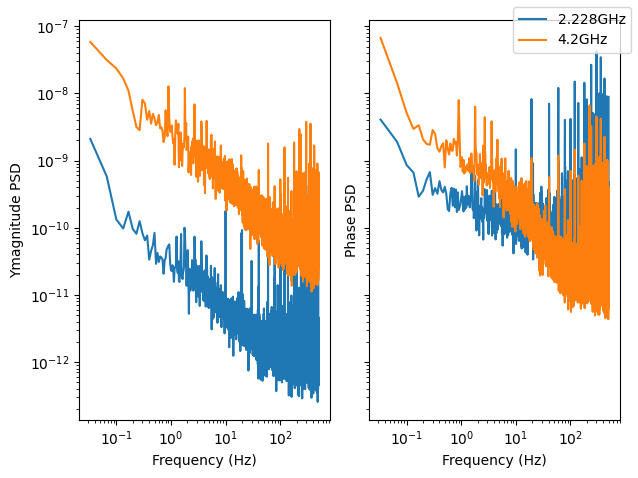

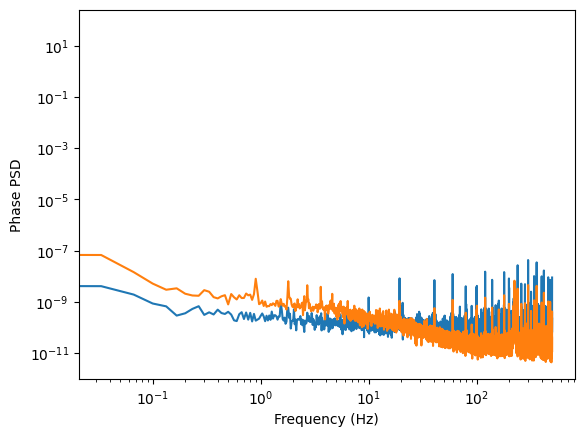

In [93]:
xf_overall_lowf = noise_floorffts_lowf["0_downsampled.csv"].xf_phase

xf_overall_highf = noise_floorffts_highf["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_highf["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_lowf[1:], (total_magyf_lowf[1:]**2)/(num_points*1E3), label = "2.228GHz")
ax1.loglog(xf_overall_highf[1:], (total_magyf_highf[1:]**2)/(num_points*1E3), label = "4.2GHz")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_lowf[1:], (total_phaseyf_lowf[1:]**2)/(num_points*1E3))
ax2.loglog(xf_overall_highf[1:],(total_phaseyf_highf[1:]**2)/(num_points*1E3))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

plt.loglog(xf_overall_lowf, (total_phaseyf_lowf**2)/(num_points*1E3), label = "2.228GHz")
plt.loglog(xf_overall_highf, (total_phaseyf_highf**2)/(num_points*1E3), label = "4.2GHz")
plt.ylabel("Phase PSD")
plt.xlabel("Frequency (Hz)")
plt.show()

In [95]:
noise_floorffts_10dBm = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmixdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_10dBm[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_10dBm.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_10dBm = []

total_magyf_10dBm = []

total_ppsd_10dBm = []

total_mpsd_10dBm = []

for value in noise_floorffts_10dBm.values():
    total_phaseyf_10dBm.append(value.yf_phase)

    total_magyf_10dBm.append(value.yf_mag)

    total_ppsd_10dBm.append(value.psd_phase)

    total_mpsd_10dBm.append(value.psd_mag)


total_phaseyf_10dBm = np.array(np.average(total_phaseyf_10dBm, axis = 0))

total_magyf_10dBm = np.array(np.average(total_magyf_10dBm, axis = 0))

total_ppsd_10dBm = np.array(np.average(total_ppsd_10dBm, axis = 0))

total_mpsd_10dBm = np.array(np.average(total_mpsd_10dBm, axis = 0))

True
True
True
True
True
True
True
True
True
True


In [96]:
noise_floorffts_19dBm = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmix19dbmdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_19dBm[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_19dBm.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_19dBm = []

total_magyf_19dBm = []

total_ppsd_19dBm = []

total_mpsd_19dBm = []

for value in noise_floorffts_19dBm.values():
    total_phaseyf_19dBm.append(value.yf_phase)

    total_magyf_19dBm.append(value.yf_mag)

    total_ppsd_19dBm.append(value.psd_phase)

    total_mpsd_19dBm.append(value.psd_mag)


total_phaseyf_19dBm = np.array(np.average(total_phaseyf_19dBm, axis = 0))

total_magyf_19dBm = np.array(np.average(total_magyf_19dBm, axis = 0))

total_ppsd_19dBm = np.array(np.average(total_ppsd_19dBm, axis = 0))

total_mpsd_19dBm = np.array(np.average(total_mpsd_19dBm, axis = 0))

True
True
True
True
True
True
True
True
True
True


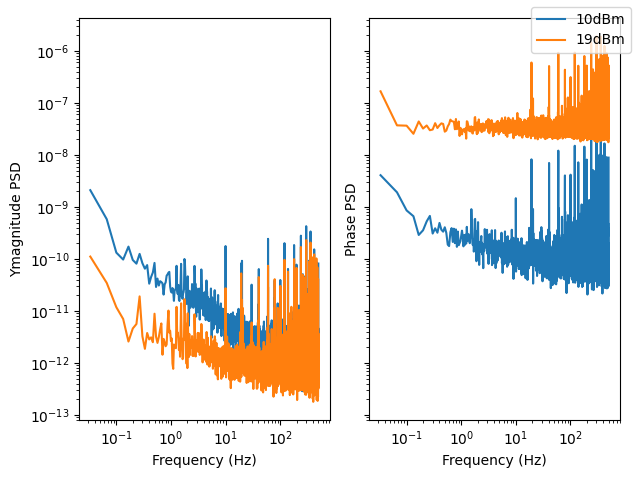

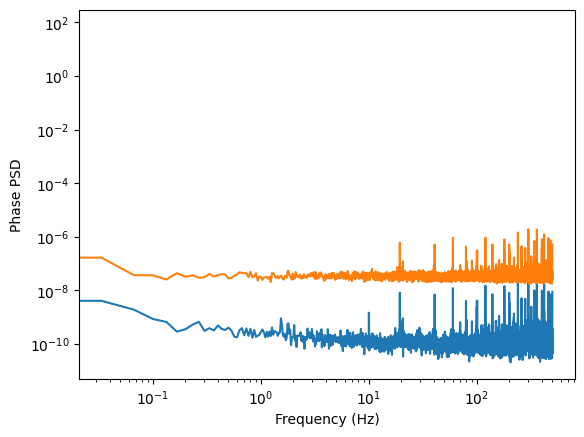

In [97]:
xf_overall_10dBm = noise_floorffts_10dBm["0_downsampled.csv"].xf_phase

xf_overall_19dBm = noise_floorffts_19dBm["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_19dBm["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_10dBm[1:], (total_magyf_10dBm[1:]**2)/(num_points*1E3), label = "10dBm")
ax1.loglog(xf_overall_19dBm[1:], (total_magyf_19dBm[1:]**2)/(num_points*1E3), label = "19dBm")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_10dBm[1:], (total_phaseyf_10dBm[1:]**2)/(num_points*1E3))
ax2.loglog(xf_overall_19dBm[1:],(total_phaseyf_19dBm[1:]**2)/(num_points*1E3))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

plt.loglog(xf_overall_10dBm, (total_phaseyf_10dBm**2)/(num_points*1E3), label = "10dBm")
plt.loglog(xf_overall_19dBm, (total_phaseyf_19dBm**2)/(num_points*1E3), label = "19dBm")
plt.ylabel("Phase PSD")
plt.xlabel("Frequency (Hz)")
plt.show()

In [98]:
noise_floorffts_phasetone = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_phasetonedownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_phasetone[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_phasetone.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_phasetone = []

total_magyf_phasetone = []

total_ppsd_phasetone = []

total_mpsd_phasetone = []

for value in noise_floorffts_phasetone.values():
    total_phaseyf_phasetone.append(value.yf_phase)

    total_magyf_phasetone.append(value.yf_mag)

    total_ppsd_phasetone.append(value.psd_phase)

    total_mpsd_phasetone.append(value.psd_mag)


total_phaseyf_phasetone = np.array(np.average(total_phaseyf_phasetone, axis = 0))

total_magyf_phasetone = np.array(np.average(total_magyf_phasetone, axis = 0))

total_ppsd_phasetone = np.array(np.average(total_ppsd_phasetone, axis = 0))

total_mpsd_phasetone = np.array(np.average(total_mpsd_phasetone, axis = 0))

noise_floorffts_bare = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmixdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_bare[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_bare.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_bare = []

total_magyf_bare = []

total_ppsd_bare = []

total_mpsd_bare = []

for value in noise_floorffts_bare.values():
    total_phaseyf_bare.append(value.yf_phase)

    total_magyf_bare.append(value.yf_mag)

    total_ppsd_bare.append(value.psd_phase)

    total_mpsd_bare.append(value.psd_mag)


total_phaseyf_bare = np.array(np.average(total_phaseyf_bare, axis = 0))

total_magyf_bare = np.array(np.average(total_magyf_bare, axis = 0))

total_ppsd_bare = np.array(np.average(total_ppsd_bare, axis = 0))

total_mpsd_bare = np.array(np.average(total_mpsd_bare, axis = 0))

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\crow104\\Desktop\\IceT_SD\\NoiseMeasurement\\Data\\noisefloor_01272026_phasetonedownsampled'

In [99]:
xf_overall_phasetone = noise_floorffts_phasetone["0_downsampled.csv"].xf_phase

xf_overall_bare = noise_floorffts_bare["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_bare["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_phasetone[1:], (total_magyf_phasetone[1:]**2)/(num_points*1E3), label = "phasetone")
ax1.loglog(xf_overall_bare[1:], (total_magyf_bare[1:]**2)/(num_points*1E3), label = "bare")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_phasetone[1:], (total_phaseyf_phasetone[1:]**2)/(num_points*1E3))
ax2.loglog(xf_overall_bare[1:],(total_phaseyf_bare[1:]**2)/(num_points*1E3))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

plt.loglog(xf_overall_phasetone, (total_phaseyf_phasetone**2)/(num_points*1E3), label = "phasetone")
plt.loglog(xf_overall_bare, (total_phaseyf_bare**2)/(num_points*1E3), label = "bare")
plt.ylabel("Phase PSD")
plt.xlabel("Frequency (Hz)")
plt.show()

KeyError: '0_downsampled.csv'

In [63]:
phasetone = measuredIQ(int(1E3), r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_phasetonetrialdown\0_downsampled.csv")

phasetone.return_phase()
phasetone.return_magnitude()

phasetone.phase_fft()
phasetone.phase_psd()

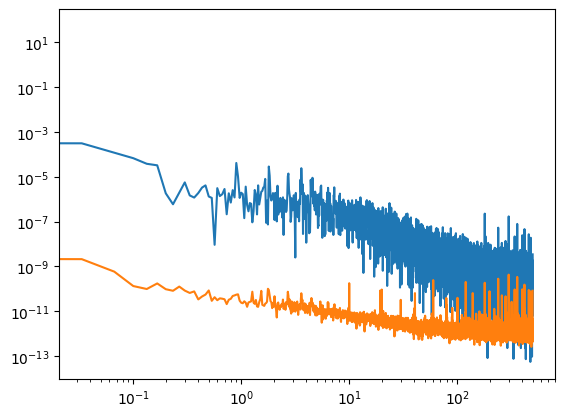

In [66]:
plt.loglog(phasetone.xf_phase, phasetone.psd_phase)

plt.loglog(xf_overall_bare, (total_magyf_10dBm**2)/(len(phasetone.phase)*int(1E3)))

plt.show()

In [ ]:
noise_floorffts = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_02032026_onresonancedownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_onresonance = []

total_magyf_onresonance = []

total_ppsd_onresonance = []

total_mpsd_onresonance = []

for value in noise_floorffts.values():
    total_phaseyf_onresonance.append(value.yf_phase)

    total_magyf_onresonance.append(value.yf_mag)

    total_ppsd_onresonance.append(value.psd_phase)

    total_mpsd_onresonance.append(value.psd_mag)


total_phaseyf_onresonance = np.array(np.average(total_phaseyf_onresonance, axis = 0))

total_magyf_onresonance = np.array(np.average(total_magyf_onresonance, axis = 0))

total_ppsd_onresonance = np.array(np.average(total_ppsd_onresonance, axis = 0))

total_mpsd_onresonance = np.array(np.average(total_mpsd_onresonance, axis = 0))

noise_floorffts_bare = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_newmixdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_bare[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_bare.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_bare = []

total_magyf_bare = []

total_ppsd_bare = []

total_mpsd_bare = []

for value in noise_floorffts_bare.values():
    total_phaseyf_bare.append(value.yf_phase)

    total_magyf_bare.append(value.yf_mag)

    total_ppsd_bare.append(value.psd_phase)

    total_mpsd_bare.append(value.psd_mag)


total_phaseyf_bare = np.array(np.average(total_phaseyf_bare, axis = 0))

total_magyf_bare = np.array(np.average(total_magyf_bare, axis = 0))

total_ppsd_bare = np.array(np.average(total_ppsd_bare, axis = 0))

total_mpsd_bare = np.array(np.average(total_mpsd_bare, axis = 0))

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


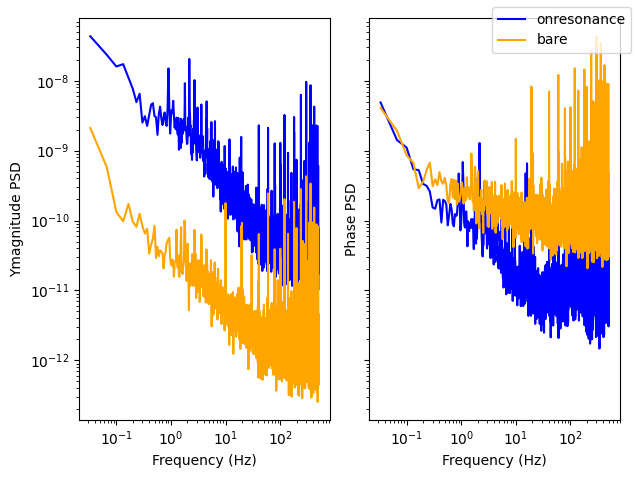

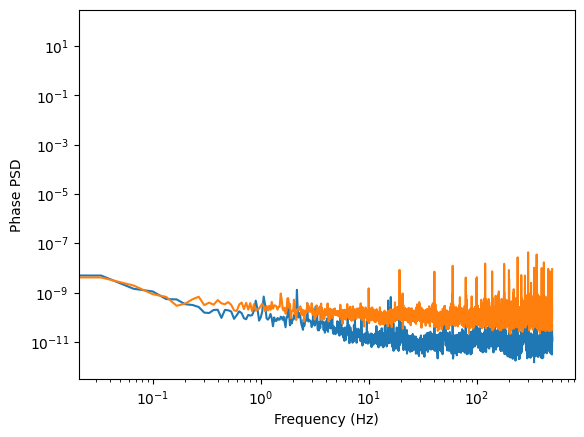

In [ ]:
xf_overall_onresonance = noise_floorffts["0_downsampled.csv"].xf_phase

xf_overall_bare = noise_floorffts_bare["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_bare["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_onresonance[1:], (total_magyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue', label = "onresonance")
ax1.loglog(xf_overall_bare[1:], (total_magyf_bare[1:]**2)/(num_points*1E3), color = 'orange', label = "bare")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_onresonance[1:], (total_phaseyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue')
ax2.loglog(xf_overall_bare[1:],(total_phaseyf_bare[1:]**2)/(num_points*1E3), color = 'orange')
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

plt.loglog(xf_overall_onresonance, (total_phaseyf_onresonance**2)/(num_points*1E3), label = "onresonance")
plt.loglog(xf_overall_bare, (total_phaseyf_bare**2)/(num_points*1E3), label = "bare")
plt.ylabel("Phase PSD")
plt.xlabel("Frequency (Hz)")
plt.show()

In [107]:
noise_floorffts_left10mhz = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_02032026_left10mhzdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_left10mhz[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_left10mhz.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_left10mhz = []

total_magyf_left10mhz = []

total_ppsd_left10mhz = []

total_mpsd_left10mhz = []

for value in noise_floorffts_left10mhz.values():
    total_phaseyf_left10mhz.append(value.yf_phase)

    total_magyf_left10mhz.append(value.yf_mag)

    total_ppsd_left10mhz.append(value.psd_phase)

    total_mpsd_left10mhz.append(value.psd_mag)


total_phaseyf_left10mhz = np.array(np.average(total_phaseyf_left10mhz, axis = 0))

total_magyf_left10mhz = np.array(np.average(total_magyf_left10mhz, axis = 0))

total_ppsd_left10mhz = np.array(np.average(total_ppsd_left10mhz, axis = 0))

total_mpsd_left10mhz = np.array(np.average(total_mpsd_left10mhz, axis = 0))

True
True
True
True
True
True
True
True
True
True


C:\Users\crow104\AppData\Local\Temp\ipykernel_24824\1885350149.py:25: RuntimeWarning: divide by zero encountered in divide
  self.phase = np.arctan(self.Q/self.I)


In [108]:
noise_floorffts_right10mhz = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_02032026_right10mhzdownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_right10mhz[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_right10mhz.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_right10mhz = []

total_magyf_right10mhz = []

total_ppsd_right10mhz = []

total_mpsd_right10mhz = []

for value in noise_floorffts_right10mhz.values():
    total_phaseyf_right10mhz.append(value.yf_phase)

    total_magyf_right10mhz.append(value.yf_mag)

    total_ppsd_right10mhz.append(value.psd_phase)

    total_mpsd_right10mhz.append(value.psd_mag)


total_phaseyf_right10mhz = np.array(np.average(total_phaseyf_right10mhz, axis = 0))

total_magyf_right10mhz = np.array(np.average(total_magyf_right10mhz, axis = 0))

total_ppsd_right10mhz = np.array(np.average(total_ppsd_right10mhz, axis = 0))

total_mpsd_right10mhz = np.array(np.average(total_mpsd_right10mhz, axis = 0))

True
True
True
True
True
True
True
True
True
True


C:\Users\crow104\AppData\Local\Temp\ipykernel_24824\1885350149.py:25: RuntimeWarning: divide by zero encountered in divide
  self.phase = np.arctan(self.Q/self.I)


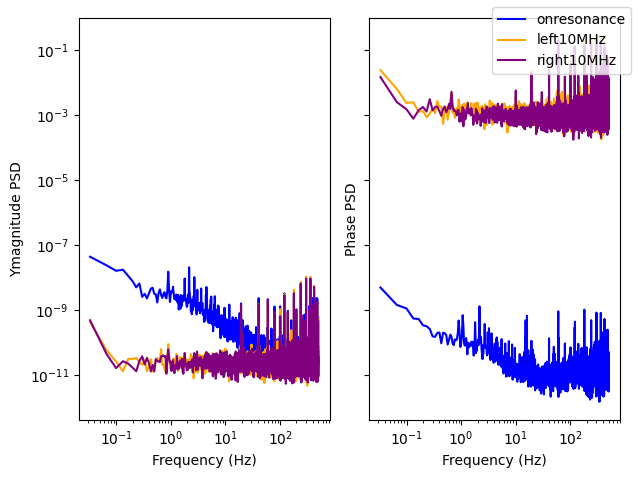

In [ ]:
xf_overall_onresonance = noise_floorffts_onresonance["0_downsampled.csv"].xf_phase

xf_overall_left = noise_floorffts_left10mhz["0_downsampled.csv"].xf_phase

xf_overall_right = noise_floorffts_right10mhz["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_onresonance["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_onresonance[1:], (total_magyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue', label = "onresonance")
ax1.loglog(xf_overall_left[1:], (total_magyf_left10mhz[1:]**2)/(num_points*1E3), color = 'orange', label = "left10MHz")
ax1.loglog(xf_overall_right[1:], (total_magyf_right10mhz[1:]**2)/(num_points*1E3), label = "right10MHz", color = "purple")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_onresonance[1:], (total_phaseyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue')
ax2.loglog(xf_overall_left[1:], (total_phaseyf_left10mhz[1:]**2)/(num_points*1E3), color = "orange" )
ax2.loglog(xf_overall_right[1:], (total_phaseyf_right10mhz[1:]**2)/(num_points*1E3), color = "purple")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

# plt.loglog(xf_overall_onresonance, (total_phaseyf_onresonance**2)/(num_points*1E3), label = "onresonance")
# plt.loglog(xf_overall_bare, (total_phaseyf_bare**2)/(num_points*1E3), label = "bare")
# plt.ylabel("Phase PSD")
# plt.xlabel("Frequency (Hz)")
# plt.show()

In [70]:
noise_floorffts = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_02182026_100averagedownsampled_nightime"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf = []

total_magyf = []

total_ppsd = []

total_mpsd = []

for value in noise_floorffts.values():
    total_phaseyf.append(value.yf_phase)

    total_magyf.append(value.yf_mag)

    total_ppsd.append(value.psd_phase)

    total_mpsd.append(value.psd_mag)


total_phaseyf = np.array(np.average(total_phaseyf, axis = 0))

total_magyf = np.array(np.average(total_magyf, axis = 0))

total_ppsd = np.array(np.average(total_ppsd, axis = 0))

total_mpsd = np.array(np.average(total_mpsd, axis = 0))

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


In [71]:
noise_floorffts_onresonance = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-25_17_29_20.624129"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    noise_floorffts_onresonance[file] = measuredIQ(int(1E3), filepath)

for value in noise_floorffts_onresonance.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_onresonance = []

total_magyf_onresonance = []

total_ppsd_onresonance = []

total_mpsd_onresonance = []

for value in noise_floorffts_onresonance.values():
    total_phaseyf_onresonance.append(value.yf_phase)

    total_magyf_onresonance.append(value.yf_mag)

    total_ppsd_onresonance.append(value.psd_phase)

    total_mpsd_onresonance.append(value.psd_mag)


total_phaseyf_onresonance = np.array(np.average(total_phaseyf_onresonance, axis = 0))

total_magyf_onresonance = np.array(np.average(total_magyf_onresonance, axis = 0))

total_ppsd_onresonance = np.array(np.average(total_ppsd_onresonance, axis = 0))

total_mpsd_onresonance = np.array(np.average(total_mpsd_onresonance, axis = 0))

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


In [72]:
neonffts_neononresonance = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-26_18_06_39.155537"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    neonffts_neononresonance[file] = measuredIQ(int(1E3), filepath)

for value in neonffts_neononresonance.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_neononresonance = []

total_magyf_neononresonance = []

total_ppsd_neononresonance = []

total_mpsd_neononresonance = []

for value in neonffts_neononresonance.values():
    total_phaseyf_neononresonance.append(value.yf_phase)

    total_magyf_neononresonance.append(value.yf_mag)

    total_ppsd_neononresonance.append(value.psd_phase)

    total_mpsd_neononresonance.append(value.psd_mag)


total_phaseyf_neononresonance = np.array(np.average(total_phaseyf_neononresonance, axis = 0))

total_magyf_neononresonance = np.array(np.average(total_magyf_neononresonance, axis = 0))

total_ppsd_neononresonance = np.array(np.average(total_ppsd_neononresonance, axis = 0))

total_mpsd_neononresonance = np.array(np.average(total_mpsd_neononresonance, axis = 0))

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


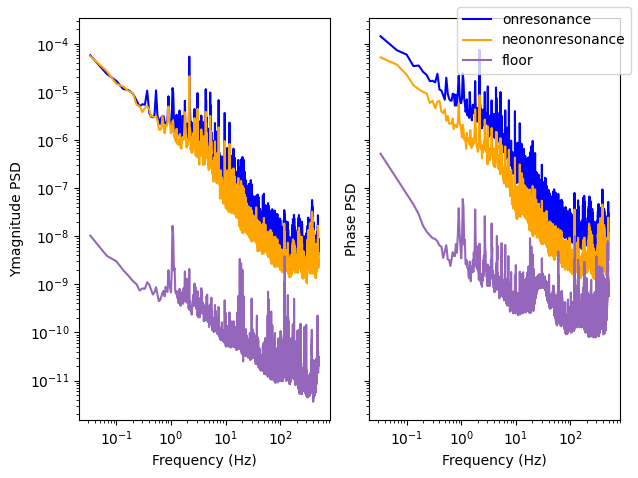

In [74]:
xf_overall_onresonance = noise_floorffts_onresonance["0_downsampled.csv"].xf_phase

xf_neon_onresonance = neonffts_neononresonance["0_downsampled.csv"].xf_phase

num_points = len(noise_floorffts_onresonance["0_downsampled.csv"].phase)
chop_frequency = 1E3


fig, (ax1, ax2) = plt.subplots(1, 2, sharey = True)
ax1.loglog(xf_overall_onresonance[1:], (total_magyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue', label = "onresonance")
ax1.loglog(xf_neon_onresonance[1:], (total_magyf_neononresonance[1:]**2)/(num_points*1E3), color = 'orange', label = "neononresonance")
ax1.loglog(xf_overall_onresonance[1:], (total_magyf[1:]**2)/(num_points*1E3), color = 'tab:purple', label = 'floor')
#ax1.loglog(xf_overall_right[1:], (total_magyf_right10mhz[1:]**2)/(num_points*1E3), label = "right10MHz", color = "purple")
ax1.set_ylabel("Ymagnitude PSD")
ax1.set_xlabel("Frequency (Hz)")
ax2.loglog(xf_overall_onresonance[1:], (total_phaseyf_onresonance[1:]**2)/(num_points*1E3), color = 'blue')
ax2.loglog(xf_neon_onresonance[1:], (total_phaseyf_neononresonance[1:]**2)/(num_points*1E3), color = "orange" )
ax2.loglog(xf_overall_onresonance[1:], (total_phaseyf[1:]**2)/(num_points*1E3), color = 'tab:purple')
#ax2.loglog(xf_overall_right[1:], (total_phaseyf_right10mhz[1:]**2)/(num_points*1E3), color = "purple")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Phase PSD")
fig.legend()
plt.tight_layout()
plt.show()

# plt.loglog(xf_overall_onresonance, (total_phaseyf_onresonance**2)/(num_points*1E3), label = "onresonance")
# plt.loglog(xf_overall_bare, (total_phaseyf_bare**2)/(num_points*1E3), label = "bare")
# plt.ylabel("Phase PSD")
# plt.xlabel("Frequency (Hz)")
# plt.show()

C:\Users\crow104\AppData\Local\Temp\ipykernel_18500\1357843964.py:4: RuntimeWarning: divide by zero encountered in divide
  return A/(f**(alpha)) + c


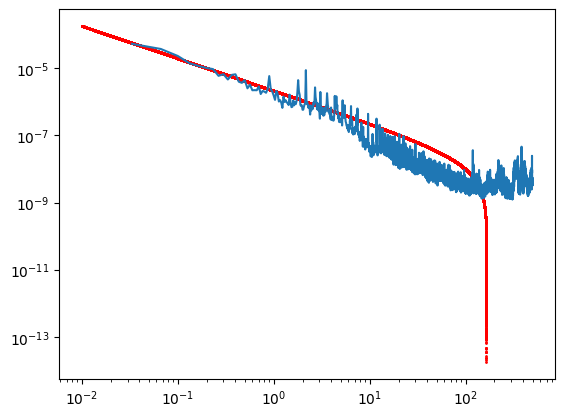

In [76]:
psd = (total_phaseyf_neononresonance**2)/(num_points*chop_frequency)

def noise_model(f, A, alpha, c):
    return A/(f**(alpha)) + c


param, cov = curve_fit(noise_model, xf_neon_onresonance[1:], psd[1:], p0 = [1E-3, 1.0, 1E-3])


fit_x = np.linspace(0, xf_neon_onresonance, 1000)

fit_y = noise_model(fit_x, *param)

plt.plot(xf_neon_onresonance[1:], psd[1:])
plt.scatter(fit_x[fit_x > 0.01], fit_y[fit_x > 0.01], s = 1, color = 'red')

plt.yscale('log')
plt.xscale('log')

plt.show()

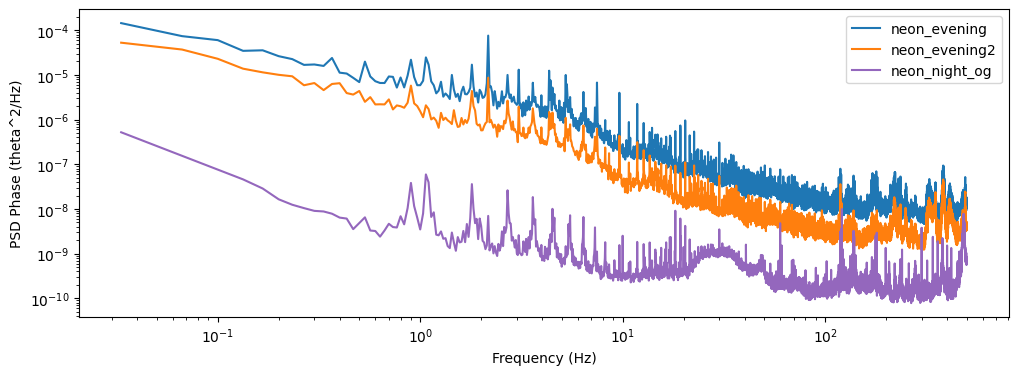

In [77]:
plt.figure(figsize = [12, 4])

psd_resonance = (total_phaseyf_onresonance**2)/(num_points*chop_frequency)

white_noise_median = np.median(psd[xf_neon_onresonance > 2E0])

resonance_noise_median = np.median(psd_resonance[xf_overall_onresonance > 2E0])

psd_floor = (total_phaseyf**2)/(num_points*chop_frequency)

#white_noise_floor = np.median(psd_floor[xf_overall_onresonance > 2E0])


plt.loglog(xf_overall_onresonance[1:], psd_resonance[1:], label = 'neon_evening')
#plt.axhline(resonance_noise_median, color = 'black')

plt.loglog(xf_neon_onresonance[1:], psd[1:], label = 'neon_evening2')
#plt.axhline(white_noise_median, color = 'black')

plt.loglog(xf_overall_onresonance[1:], psd_floor[1:], label = "neon_night_og", color = "tab:purple")

#plt.axhline(white_noise_floor, color = 'black')

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD Phase (theta^2/Hz)")
plt.legend()
plt.show()

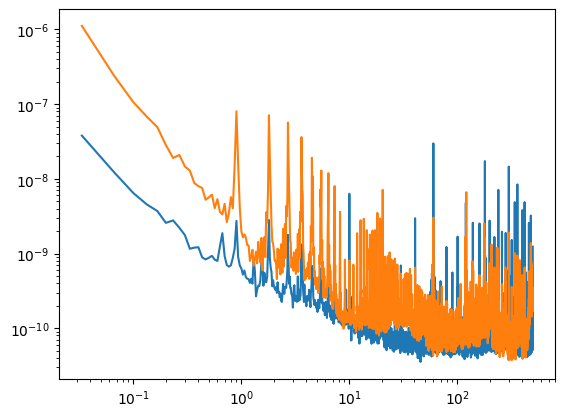

In [19]:
plt.loglog(xf_overall_onresonance[1:], psd_resonance[1:])
plt.loglog(xf_neon_onresonance[1:], psd_neon2[1:])

plt.show()

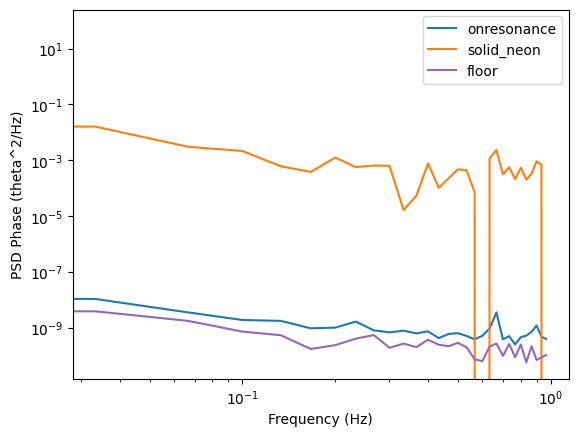

In [46]:
white_noise_subtract_resonance = psd_resonance - resonance_noise_median

white_noise_subtract_neon = psd - white_noise_median

white_noise_floor_subtract = psd_floor - white_noise_floor


plt.loglog(xf_overall_onresonance[xf_overall_onresonance < 1E0], white_noise_subtract_resonance[xf_overall_onresonance < 1E0], label = 'onresonance')

plt.loglog(xf_neon_onresonance[xf_neon_onresonance < 1E0], white_noise_subtract_neon[xf_neon_onresonance < 1E0], label = 'solid_neon')

plt.loglog(xf_overall_onresonance[xf_overall_onresonance < 1E0], white_noise_floor_subtract[xf_overall_onresonance < 1E0], label = 'floor', color = 'tab:purple')

plt.legend()
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD Phase (theta^2/Hz)")
plt.show()

In [81]:
neonffts_neononresonance = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_02172026_10dbm100averagedownsampled"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    neonffts_neononresonance[file] = measuredIQ(int(1E3), filepath)

for value in neonffts_neononresonance.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_neononresonance = []

total_magyf_neononresonance = []

total_ppsd_neononresonance = []

total_mpsd_neononresonance = []

for value in neonffts_neononresonance.values():
    total_phaseyf_neononresonance.append(value.yf_phase)

    total_magyf_neononresonance.append(value.yf_mag)

    total_ppsd_neononresonance.append(value.psd_phase)

    total_mpsd_neononresonance.append(value.psd_mag)


total_phaseyf_neononresonance = np.array(np.average(total_phaseyf_neononresonance, axis = 0))

total_magyf_neononresonance = np.array(np.average(total_magyf_neononresonance, axis = 0))

total_ppsd_neononresonance = np.array(np.average(total_ppsd_neononresonance, axis = 0))

total_mpsd_neononresonance = np.array(np.average(total_mpsd_neononresonance, axis = 0))


psd_neon = (total_phaseyf_neononresonance**2)/(num_points*chop_frequency)

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


In [82]:
neon2ffts_neon2onresonance = {}

folderpath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloorrephased_downsampled_2026-02-23_18_19_27.885947"
for file in os.listdir(folderpath):
    filepath = os.path.join(folderpath, file)

    neon2ffts_neon2onresonance[file] = measuredIQ(int(1E3), filepath)

for value in neon2ffts_neon2onresonance.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()
    value.magnitude_psd()
    value.phase_psd()


total_phaseyf_neon2onresonance = []

total_magyf_neon2onresonance = []

total_ppsd_neon2onresonance = []

total_mpsd_neon2onresonance = []

for value in neon2ffts_neon2onresonance.values():
    total_phaseyf_neon2onresonance.append(value.yf_phase)

    total_magyf_neon2onresonance.append(value.yf_mag)

    total_ppsd_neon2onresonance.append(value.psd_phase)

    total_mpsd_neon2onresonance.append(value.psd_mag)


total_phaseyf_neon2onresonance = np.array(np.average(total_phaseyf_neon2onresonance, axis = 0))

total_magyf_neon2onresonance = np.array(np.average(total_magyf_neon2onresonance, axis = 0))

total_ppsd_neon2onresonance = np.array(np.average(total_ppsd_neon2onresonance, axis = 0))

total_mpsd_neon2onresonance = np.array(np.average(total_mpsd_neon2onresonance, axis = 0))


psd_neon2 = (total_phaseyf_neon2onresonance**2)/(num_points*chop_frequency)

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


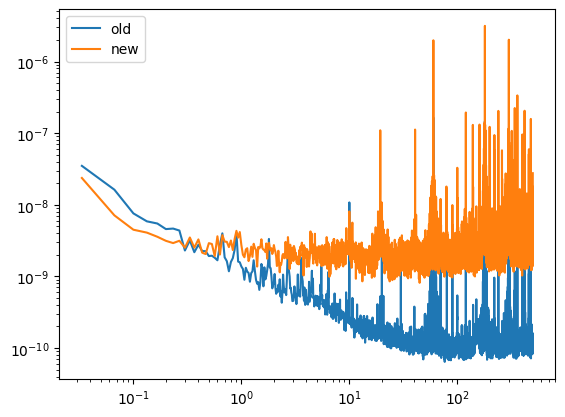

In [84]:
plt.loglog(xf_neon_onresonance[1:], psd_neon[1:], label = 'old')
plt.loglog(xf_neon_onresonance[1:], psd_neon2[1:], label = 'new')

plt.legend()
plt.show()

In [29]:
print (len(os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-25_17_29_20.624129")))

100


In [69]:
import pandas as pd
for file in os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-25_17_29_20.624129"):

    filepath = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-25_17_29_20.624129" + '\\' + file
# Load without header
    df = pd.read_csv(filepath, header=None)

# Add column names
    df.columns = ["I", "Q"]

# Save
    df.to_csv(filepath, index=False)